In [1]:
import pandas as pd
import protfasta
import glob

# Gathering all inputs

## 1. SK Interpro evidence 1 and 2 sequences

In [2]:
def return_df(fasta_path):
    fasta_dict = protfasta.read_fasta(fasta_path, invalid_sequence_action='remove')
    return pd.DataFrame({'id' : fasta_dict.keys(), 'seq' : fasta_dict.values()})

In [3]:
sk_seqs = return_df("data/interpro_uniprot_evid_1_2.fasta")
sk_seqs

,id,seq
0,sp|O75603|GCM2_HUMAN Chorion-specific transcri...,MPAAAVQEAVGVCSYGMQLSWDINDPQMPQELALFDQFREWPDGYV...
1,sp|P70348|GCM1_MOUSE Chorion-specific transcri...,MELDDFDPEDKEILSWDINDVKLPQNVKTTDWFQEWPDSYVKHIYS...
2,sp|Q27403|GCM_DROME Transcription factor glial...,MVLNGMPITMPVPMPVPMPVPSPPATKSRVAIDWDINDSKMPSVGE...
3,sp|Q9NP62|GCM1_HUMAN Chorion-specific transcri...,MEPDDFDSEDKEILSWDINDVKLPQNVKKTDWFQEWPDSYAKHIYS...
4,sp|B7ZQJ9|GT2D1_XENLA General transcription fa...,MALAGKQYEGSLNNSRPNLWPSSIPGGKNEIITSLVTALDSMCTAL...
...,...,...
137431,tr|A0A411G830|A0A411G830_9HYME HTH CENPB-type ...,VRRFIINIDILFSFFDSSFVLYSKMTDSNSNANYQVMDLNSNDVTS...
137432,tr|A0A6F9DP70|A0A6F9DP70_9ASCI Uncharacterized...,MEEKATASPKTPGFRKIFSVNEEEIIGKFLISCWKKKLRVPNEVLF...
137433,tr|A0A8E6LR96|A0A8E6LR96_9HYPO CENP-B-like pro...,MADSTTDPALVAAEPTDIPSVPAPASASSKERNSLTLDQRRALRRW...
137434,tr|T1PL60|T1PL60_MUSDO Regulator of RNA polyme...,MYDELPVYQRVASAFKCSWEQIKNVVANRKQILKYYASCQIIDVMK...


In [4]:
# sk_seqs = sk_seqs[(sk_seqs["seq"].str.len() >= 53) & (sk_seqs["seq"].str.len() < 1731)]
# sk_seqs

## 2. CL yeast orthologs

In [5]:
# TFs homologous to s.c. yeast TFs
cl_seqs = return_df("data/cl_seqs.fasta")
cl_seqs

,id,seq
0,g002981.m1_ashbya_aceri.final,MNRSDELQDAEDSGQQRYETYSCSRCRRLKKRCSKELPRCFSCEAA...
1,g001536.m1_brettanomyces_anomalus.final,MSDKPHNQYACTRCRRLKKKCSKEFPRCANCRKQNKVCEYVERKNK...
2,C1_01200W_A_candida_albicans.cgd,MRPIDSIVSKFRVQKHTSNLADNPAVLKHPEDMPKLTSCLRCRKLK...
3,g000106.m1_candida_albicans.final,MRPIDSIVSKFRVQKHTSNLADNPAVLKHPEDMPKLTSCLRCRKLK...
4,g001050.m1_candida_dubliniensis.final,MRPTDSIVSKFRVQKPTSNLANNPAVLRHPENMPKLTSCLRCRKLK...
...,...,...
172849,g003574.m1_yHMPu5000037837_Vanderwaltozyma_ver...,MDTTNSLFDSINTITTTNLSTSSTTTDNVKDFNNLFDDDFDLGIDF...
172850,g000938.m1_yHMPu5000040961_kazachstania_turice...,MQHHNMELDNLFDLDADIDFETAYQLFSNLDNIQEKNIDIFTQNVH...
172851,g003697.m1_yHMPu5000040963_lachancea_quebecuen...,MDTDRLLDIFDFDLEIDFETAYEMINKEDQNAKHATERSLVENEVD...
172852,g004154.m1_yHQL494_Lachancea_sp_nov_plate34_PL...,MENEHLLDVFDYDLDIDFETAYEMINNEDQVFKGNNENHMAIDPEV...


In [6]:
import numpy as np
np.percentile(cl_seqs["seq"].str.len(), 99)

1329.0

In [7]:
cl_seqs = cl_seqs.drop_duplicates(subset = "seq")
cl_seqs

,id,seq
0,g002981.m1_ashbya_aceri.final,MNRSDELQDAEDSGQQRYETYSCSRCRRLKKRCSKELPRCFSCEAA...
1,g001536.m1_brettanomyces_anomalus.final,MSDKPHNQYACTRCRRLKKKCSKEFPRCANCRKQNKVCEYVERKNK...
2,C1_01200W_A_candida_albicans.cgd,MRPIDSIVSKFRVQKHTSNLADNPAVLKHPEDMPKLTSCLRCRKLK...
3,g000106.m1_candida_albicans.final,MRPIDSIVSKFRVQKHTSNLADNPAVLKHPEDMPKLTSCLRCRKLK...
4,g001050.m1_candida_dubliniensis.final,MRPTDSIVSKFRVQKPTSNLANNPAVLRHPENMPKLTSCLRCRKLK...
...,...,...
172849,g003574.m1_yHMPu5000037837_Vanderwaltozyma_ver...,MDTTNSLFDSINTITTTNLSTSSTTTDNVKDFNNLFDDDFDLGIDF...
172850,g000938.m1_yHMPu5000040961_kazachstania_turice...,MQHHNMELDNLFDLDADIDFETAYQLFSNLDNIQEKNIDIFTQNVH...
172851,g003697.m1_yHMPu5000040963_lachancea_quebecuen...,MDTDRLLDIFDFDLEIDFETAYEMINKEDQNAKHATERSLVENEVD...
172852,g004154.m1_yHQL494_Lachancea_sp_nov_plate34_PL...,MENEHLLDVFDYDLDIDFETAYEMINNEDQVFKGNNENHMAIDPEV...


In [8]:
cl_seqs[(cl_seqs["seq"].str.len()<53)]

,id,seq
5552,g011087.m1_yHMPu5000035263_Candida_solani_SPAD...,SSFLRIWVSENAQNYQILNAKKPDAYKFKLIQFFININLSINYGLV...
24035,g000758.m1_yHMPu5000035663_Meyerozyma_guillier...,MSAANPMILTGDSFESADVFNSASATSDRTLGSQMLAMKASENSEE...
29540,g001009.m1_yHMPu5000040795_metschnikowia_matae...,PILEDLNDYMNLYEKEFNECLLPVHSYANSQTLRNPMIDNFENIPSFH
45751,g000838.m1_yHMPu5000037895_candida_jaroonii_18...,MDEYDNSEVNNEEEYDRLLLLSLILQINLDSCFSVYENFDLIFAIGDHM
47962,g000779.m1_yHMPu5000038063_candida_xylanilytic...,MNFEPTDYIQHLNLDLDSVVSPTMTQQQLDHELDLFSQANDFFSLDVLG
54929,g001649.m1_yHMPu5000035711_botryozyma_cognata_...,MSYSSKGEYSNNNTNVNGFTQFYNPNSTFSSYNDSTEAYPDSLSRSMRP
59078,g002839.m1_yHMPu5000040949_metschnikowia_hawai...,QPTKWEFRHSATQIRKGDVDSLSLIKRKSSKIFNSPKEIVYLKPLP...
68594,g004941.m1_yHMPu5000037226_ogataea_haglerorum_...,LQEQKLKALRQEKPSTATPPPPGLFPATGADSIKTNSAELLSQLMG...
72697,g012362.m1_yHMPu5000038388_candida_inconspicua...,EIKLYNESKEALQHAHDVQQMAEMVNMVDMEGLEGIELPPKKKSKKSKK
74155,g000265.m1_yHMPu5000034950_citeromyces_hawaiie...,PDWESYDFTKLDPSSPEDKEFVNDMWAWDKPVIVNGESREIADGKVLK


In [9]:
cl_seqs[(cl_seqs["seq"].str.len() > 1891)]

,id,seq
538,g006213.m1_yHMPu5000035688_Cyberlindnera_xylos...,MKLHLFALLWSLWLFSLVSAQDNEDETEPWIEGAFVENVPTWYIHI...
7854,g000481.m1_yHMPu5000041819_magnusiomyces_starm...,MSSGNAPFISPVSSVDTPYNLPNQRQQQELPPNNYQQQYTFFSPNQ...
8166,g005008.m1_yHKB357_New_Genus_SPADES.final,LVNSAGSTIVVVEVPDLSTTTSPGPVSETTTFTLVNSAGSSIVVVE...
23119,g006333.m1_yHMPu5000041796_saccharomycopsis_fi...,MSYHRDSNSNKNETIDNDNDNDNQRDNLIPVQQHGHDQGQHTLEEL...
28454,g000223.m1_saprochaete_ingens.final,MNTQQQQQQHPPPQGPPGIPAQVQPQNSSRGGIASNNPGTQQQQQQ...
...,...,...
146424,g002499.m1_yHMPu5000034628_pichia_fermentans_1...,MDFQITREAPTRGLCRAQLTKEGRILFQTRNGLMMYDTNTGFRGKT...
153315,g000315.m1_yHMPu5000035696_hanseniaspora_singu...,MPQPTLNNTALVIQETGYSYEKHVDDFRNIMTKLLYECSNIFKQHL...
159744,g004370.m1_hanseniaspora_gamundiae.final,MSQSMTPSVSTPATSTAATFSKLQSCDRCRLKKIKCSFSSDKALNG...
160428,g002830.m1_yHMPu5000035684_kloeckera_hatyaiens...,MANSDKAKKEQQYQSCDRCRSKKIKCTYDKKSLKQCINCKNAFLEC...


In [10]:
# cl_seqs = cl_seqs[(cl_seqs["seq"].str.len() >= 53) & (cl_seqs["seq"].str.len() < 1731)]
# cl_seqs

# 3. Plant species

In [11]:
plant_seqs = return_df("data/PlantTFDB-all_TF_pep.fas")
plant_seqs

,id,seq
0,KFK36254.1 Arabis alpina|G2-like|G2-like famil...,MYSAIRSLPVDGSMGEYSDGTNLPIEACLVLTTDPKPRLRWTTELH...
1,KFK25038.1 Arabis alpina|GeBP|GeBP family protein,MAPKHTDTIQNPPMPSSSSEEESASSGEDSDSSKKHNSASDSDPIK...
2,KFK35037.1 Arabis alpina|bZIP|bZIP family protein,MTTTTTPHWPDFSSQKLPSIAATAAATAATAGQNQQNQNPSWMDEF...
3,KFK44643.1 Arabis alpina|ERF|ERF family protein,MEGERHDSTTSSSRKRSHEPAEERPASHVATMAFKEKPYRGIRMRK...
4,KFK32619.1 Arabis alpina|B3|B3 family protein,MAKPPQFFHTLVNTHLVIPKDFFSKYIQGKSVDDTVELKSDSTDIN...
...,...,...
310651,Zpz_sc00227.1.g00450.1.am.mk Zoysia pacifica|b...,MYGSTVSKDLNLPAVQPQPATGARTPPPQMSSSGLLRYRSAPSNLL...
310652,Zpz_sc01778.1.g00020.1.am.mk Zoysia pacifica|M...,MARKPNQHAAAGTGAAAEEKKERRGLWSPEEDERLFTQITCHGVST...
310653,Zpz_sc01095.1.g00030.1.sm.mk Zoysia pacifica|H...,MEGSQSRSGGGSSSPPPFLIKTYEMVEDPATNRVVSWGPGGASFVV...
310654,Zpz_sc05215.1.g00010.1.am.mk Zoysia pacifica|b...,MSDDSDKQRQCRRGVGVHELDAAMALADLAGVSPEPQKLHLQPAAA...


##  Both together now

In [12]:
all_seqs = pd.concat([sk_seqs, cl_seqs, plant_seqs])
all_seqs

,id,seq
0,sp|O75603|GCM2_HUMAN Chorion-specific transcri...,MPAAAVQEAVGVCSYGMQLSWDINDPQMPQELALFDQFREWPDGYV...
1,sp|P70348|GCM1_MOUSE Chorion-specific transcri...,MELDDFDPEDKEILSWDINDVKLPQNVKTTDWFQEWPDSYVKHIYS...
2,sp|Q27403|GCM_DROME Transcription factor glial...,MVLNGMPITMPVPMPVPMPVPSPPATKSRVAIDWDINDSKMPSVGE...
3,sp|Q9NP62|GCM1_HUMAN Chorion-specific transcri...,MEPDDFDSEDKEILSWDINDVKLPQNVKKTDWFQEWPDSYAKHIYS...
4,sp|B7ZQJ9|GT2D1_XENLA General transcription fa...,MALAGKQYEGSLNNSRPNLWPSSIPGGKNEIITSLVTALDSMCTAL...
...,...,...
310651,Zpz_sc00227.1.g00450.1.am.mk Zoysia pacifica|b...,MYGSTVSKDLNLPAVQPQPATGARTPPPQMSSSGLLRYRSAPSNLL...
310652,Zpz_sc01778.1.g00020.1.am.mk Zoysia pacifica|M...,MARKPNQHAAAGTGAAAEEKKERRGLWSPEEDERLFTQITCHGVST...
310653,Zpz_sc01095.1.g00030.1.sm.mk Zoysia pacifica|H...,MEGSQSRSGGGSSSPPPFLIKTYEMVEDPATNRVVSWGPGGASFVV...
310654,Zpz_sc05215.1.g00010.1.am.mk Zoysia pacifica|b...,MSDDSDKQRQCRRGVGVHELDAAMALADLAGVSPEPQKLHLQPAAA...


In [13]:
# Dropping duplicate sequences
all_seqs = all_seqs.drop_duplicates(subset = "seq")
all_seqs

,id,seq
0,sp|O75603|GCM2_HUMAN Chorion-specific transcri...,MPAAAVQEAVGVCSYGMQLSWDINDPQMPQELALFDQFREWPDGYV...
1,sp|P70348|GCM1_MOUSE Chorion-specific transcri...,MELDDFDPEDKEILSWDINDVKLPQNVKTTDWFQEWPDSYVKHIYS...
2,sp|Q27403|GCM_DROME Transcription factor glial...,MVLNGMPITMPVPMPVPMPVPSPPATKSRVAIDWDINDSKMPSVGE...
3,sp|Q9NP62|GCM1_HUMAN Chorion-specific transcri...,MEPDDFDSEDKEILSWDINDVKLPQNVKKTDWFQEWPDSYAKHIYS...
4,sp|B7ZQJ9|GT2D1_XENLA General transcription fa...,MALAGKQYEGSLNNSRPNLWPSSIPGGKNEIITSLVTALDSMCTAL...
...,...,...
310651,Zpz_sc00227.1.g00450.1.am.mk Zoysia pacifica|b...,MYGSTVSKDLNLPAVQPQPATGARTPPPQMSSSGLLRYRSAPSNLL...
310652,Zpz_sc01778.1.g00020.1.am.mk Zoysia pacifica|M...,MARKPNQHAAAGTGAAAEEKKERRGLWSPEEDERLFTQITCHGVST...
310653,Zpz_sc01095.1.g00030.1.sm.mk Zoysia pacifica|H...,MEGSQSRSGGGSSSPPPFLIKTYEMVEDPATNRVVSWGPGGASFVV...
310654,Zpz_sc05215.1.g00010.1.am.mk Zoysia pacifica|b...,MSDDSDKQRQCRRGVGVHELDAAMALADLAGVSPEPQKLHLQPAAA...


In [14]:
np.percentile(all_seqs["seq"].str.len(), 99)

1442.0

In [15]:
all_seqs = all_seqs[(all_seqs["seq"].str.len() <= 1442.0) & (all_seqs["seq"].str.len() >= 53)]
all_seqs

,id,seq
0,sp|O75603|GCM2_HUMAN Chorion-specific transcri...,MPAAAVQEAVGVCSYGMQLSWDINDPQMPQELALFDQFREWPDGYV...
1,sp|P70348|GCM1_MOUSE Chorion-specific transcri...,MELDDFDPEDKEILSWDINDVKLPQNVKTTDWFQEWPDSYVKHIYS...
2,sp|Q27403|GCM_DROME Transcription factor glial...,MVLNGMPITMPVPMPVPMPVPSPPATKSRVAIDWDINDSKMPSVGE...
3,sp|Q9NP62|GCM1_HUMAN Chorion-specific transcri...,MEPDDFDSEDKEILSWDINDVKLPQNVKKTDWFQEWPDSYAKHIYS...
4,sp|B7ZQJ9|GT2D1_XENLA General transcription fa...,MALAGKQYEGSLNNSRPNLWPSSIPGGKNEIITSLVTALDSMCTAL...
...,...,...
310651,Zpz_sc00227.1.g00450.1.am.mk Zoysia pacifica|b...,MYGSTVSKDLNLPAVQPQPATGARTPPPQMSSSGLLRYRSAPSNLL...
310652,Zpz_sc01778.1.g00020.1.am.mk Zoysia pacifica|M...,MARKPNQHAAAGTGAAAEEKKERRGLWSPEEDERLFTQITCHGVST...
310653,Zpz_sc01095.1.g00030.1.sm.mk Zoysia pacifica|H...,MEGSQSRSGGGSSSPPPFLIKTYEMVEDPATNRVVSWGPGGASFVV...
310654,Zpz_sc05215.1.g00010.1.am.mk Zoysia pacifica|b...,MSDDSDKQRQCRRGVGVHELDAAMALADLAGVSPEPQKLHLQPAAA...


In [17]:
protfasta.write_fasta(dict(zip(all_seqs["id"], all_seqs["seq"])), "data/CL_SK_plant_input.fasta")

# Remove seqences with low disorder

In [ ]:
# python ../other_scripts/calculate_properties.py -i data/CL_SK_plant_input.fasta -o ../notebooks/data/CL_SK_plant_seq_props.csv
CL_SK_plant_seq_props = pd.read_csv("../output/CL_SK_plant_seq_props.csv")
CL_SK_plant_seq_props

In [60]:
# This is from Sanjana, currently not sure where is this file located? 
# Generate this file with this python command run from the notebooks folder: 
# python ../other_scripts/calculate_properties.py -i data/CL_SK_plant_input.fasta -o ../notebooks/data/CL_SK_plant_seq_props.csv
CL_SK_plant_seq_props = pd.read_csv("../output/CL_SK_plant_seq_props.csv")
CL_SK_plant_seq_props

,id,seq,net charge,hydrophobics_prop,percent_disorder
0,tr|A0A0B4K6B8|A0A0B4K6B8_DROME Modifier of mdg...,MADDEQFSLCWNNFNTNLSAGFHESLCRGDLVDVSLAAEGQIVKAH...,-9,0.106472,69.311
1,tr|A0A0B4K7A6|A0A0B4K7A6_DROME Modifier of mdg...,MADDEQFSLCWNNFNTNLSAGFHESLCRGDLVDVSLAAEGQIVKAH...,-14,0.109804,63.922
2,sp|A0A5S9MMK5|FPEB1_CAEEL FLYWCH-type zinc fin...,MMTTTVQKNCWRLDQTMLGLEKPGSSDISSSSTDTSAISPISVSSM...,6,0.128668,67.494
3,sp|Q4VC44|FWCH1_HUMAN FLYWCH-type zinc finger-...,MPLPEPSEQEGESVKAGQEPSPKPGTDVIPAAPRKPREFSKLVLLT...,10,0.162011,52.793
4,sp|Q86B87|MMD4_DROME Modifier of mdg4 OS=Droso...,MADDEQFSLCWNNFNTNLSAGFHESLCRGDLVDVSLAAEGQIVKAH...,-26,0.118033,68.033
...,...,...,...,...,...
576611,Zpz_sc00227.1.g00450.1.am.mk Zoysia pacifica|b...,MYGSTVSKDLNLPAVQPQPATGARTPPPQMSSSGLLRYRSAPSNLL...,11,0.122807,72.515
576612,Zpz_sc01778.1.g00020.1.am.mk Zoysia pacifica|M...,MARKPNQHAAAGTGAAAEEKKERRGLWSPEEDERLFTQITCHGVST...,-3,0.150235,30.516
576613,Zpz_sc01095.1.g00030.1.sm.mk Zoysia pacifica|H...,MEGSQSRSGGGSSSPPPFLIKTYEMVEDPATNRVVSWGPGGASFVV...,-23,0.151927,58.050
576614,Zpz_sc05215.1.g00010.1.am.mk Zoysia pacifica|b...,MSDDSDKQRQCRRGVGVHELDAAMALADLAGVSPEPQKLHLQPAAA...,4,0.112450,81.124


/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


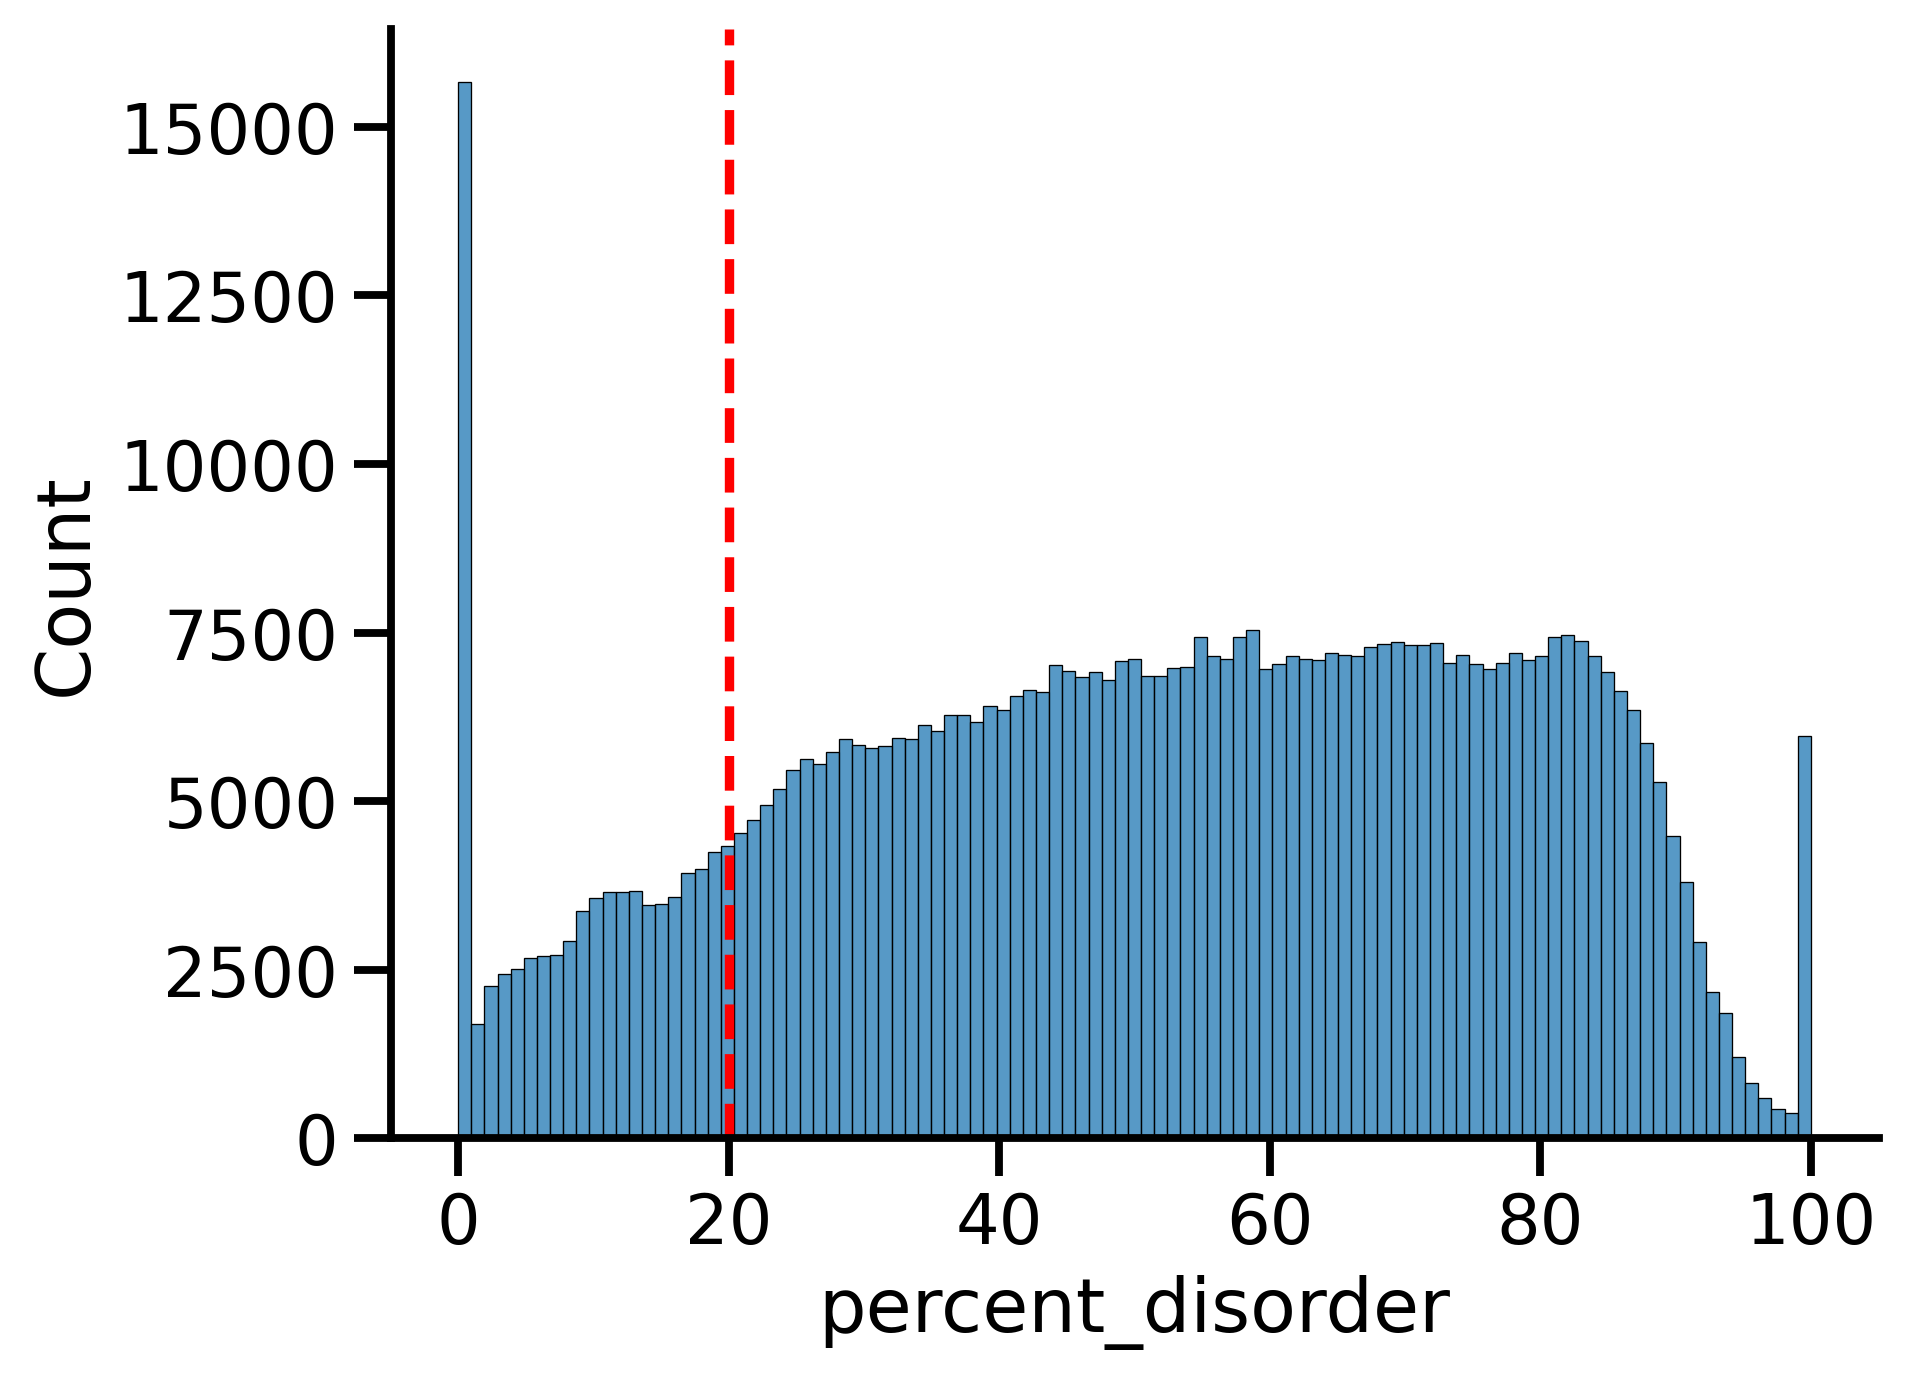

In [70]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_context('talk')
plt.figure(dpi = 300)
sns.histplot(CL_SK_plant_seq_props["percent_disorder"])
plt.axvline(20, color = 'red', linestyle = 'dashed')
sns.despine()

In [72]:
CL_SK_plant_seqs_disord_thresh = CL_SK_plant_seq_props[CL_SK_plant_seq_props["percent_disorder"] >= 20][["id", "seq"]]
CL_SK_plant_seqs_disord_thresh

,id,seq
0,tr|A0A0B4K6B8|A0A0B4K6B8_DROME Modifier of mdg...,MADDEQFSLCWNNFNTNLSAGFHESLCRGDLVDVSLAAEGQIVKAH...
1,tr|A0A0B4K7A6|A0A0B4K7A6_DROME Modifier of mdg...,MADDEQFSLCWNNFNTNLSAGFHESLCRGDLVDVSLAAEGQIVKAH...
2,sp|A0A5S9MMK5|FPEB1_CAEEL FLYWCH-type zinc fin...,MMTTTVQKNCWRLDQTMLGLEKPGSSDISSSSTDTSAISPISVSSM...
3,sp|Q4VC44|FWCH1_HUMAN FLYWCH-type zinc finger-...,MPLPEPSEQEGESVKAGQEPSPKPGTDVIPAAPRKPREFSKLVLLT...
4,sp|Q86B87|MMD4_DROME Modifier of mdg4 OS=Droso...,MADDEQFSLCWNNFNTNLSAGFHESLCRGDLVDVSLAAEGQIVKAH...
...,...,...
576611,Zpz_sc00227.1.g00450.1.am.mk Zoysia pacifica|b...,MYGSTVSKDLNLPAVQPQPATGARTPPPQMSSSGLLRYRSAPSNLL...
576612,Zpz_sc01778.1.g00020.1.am.mk Zoysia pacifica|M...,MARKPNQHAAAGTGAAAEEKKERRGLWSPEEDERLFTQITCHGVST...
576613,Zpz_sc01095.1.g00030.1.sm.mk Zoysia pacifica|H...,MEGSQSRSGGGSSSPPPFLIKTYEMVEDPATNRVVSWGPGGASFVV...
576614,Zpz_sc05215.1.g00010.1.am.mk Zoysia pacifica|b...,MSDDSDKQRQCRRGVGVHELDAAMALADLAGVSPEPQKLHLQPAAA...


In [73]:
protfasta.write_fasta(dict(zip(CL_SK_plant_seqs_disord_thresh["id"], CL_SK_plant_seqs_disord_thresh["seq"])), "../data/CL_SK_plant_seqs_disord_thresh.fasta")

In [8]:
seqs = protfasta.read_fasta("../output/interpro_uniprot_evid_1_2.fasta")
seqs = pd.DataFrame({"id" : seqs.keys(), "seq" : seqs.values()})
seqs["uniprotID"] = seqs["id"].str.split("|").str[1]
seqs = pd.merge(seqs, clusters, on = "uniprotID")
seqs

,id,seq,uniprotID,cluster_centroid
0,tr|A0A0B4K6B8|A0A0B4K6B8_DROME Modifier of mdg...,MADDEQFSLCWNNFNTNLSAGFHESLCRGDLVDVSLAAEGQIVKAH...,A0A0B4K6B8,A0A023ESS1
1,tr|A0A0B4K7A6|A0A0B4K7A6_DROME Modifier of mdg...,MADDEQFSLCWNNFNTNLSAGFHESLCRGDLVDVSLAAEGQIVKAH...,A0A0B4K7A6,A0A023ESS1
2,sp|A0A5S9MMK5|FPEB1_CAEEL FLYWCH-type zinc fin...,MMTTTVQKNCWRLDQTMLGLEKPGSSDISSSSTDTSAISPISVSSM...,A0A5S9MMK5,A8XJ98
3,sp|Q4VC44|FWCH1_HUMAN FLYWCH-type zinc finger-...,MPLPEPSEQEGESVKAGQEPSPKPGTDVIPAAPRKPREFSKLVLLT...,Q4VC44,Q4VC44
4,sp|Q86B87|MMD4_DROME Modifier of mdg4 OS=Droso...,MADDEQFSLCWNNFNTNLSAGFHESLCRGDLVDVSLAAEGQIVKAH...,Q86B87,A0A023ESS1
...,...,...,...,...
137431,tr|W8C846|W8C846_CERCA (Mediterranean fruit fl...,MNNITRLLANCTLNTTRCHLKYNAAALTAAIQLRGKCKVVVKPAPG...,W8C846,A0A0P4VQK3
137432,tr|W8CA25|W8CA25_CERCA (Mediterranean fruit fl...,MAGRPRRQAATRTAQIIEISDSEDDNSVSKNKRRRRDSSFSPPPTK...,W8CA25,Q9N4L5
137433,tr|W8QUS6|W8QUS6_MIMNO Cold shock domain prote...,MSDSEKQPEEKEEPKKNVIATKVTGTVKWFNVKSGYGFINRDDTKE...,W8QUS6,W8QUS6
137434,tr|X5CQH7|X5CQH7_9EUKA 30S plastidal ribosomal...,MSSARPLVLIASLLGASEALQSCHTRLVSSRVAATPRAAWALTMCD...,X5CQH7,X5CQH7


In [ ]:
cluster_counts = seqs["cluster_centroid"].value_counts()
cluster_counts

In [ ]:
import seaborn as sns
sns.lineplot(seqs["cluster_centroid"].value_counts())

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):

KeyboardInterrupt



Error in callback <function _draw_all_if_interactive at 0x14f25c64f100> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 